# Conversational Analytics: Ingesting & Exploring the ABCD Dataset

**Goal:** Prepare and explore the Action-Based Conversations Dataset (ABCD) for post-hoc conversation state tracking (DST) and action state tracking (AST) analytics, aligned with `ANALYSIS_PLAN.md`.

The data has been pre-processed into optimized Parquet tables and an indexed SQLite database, with helper functions provided by the `abcd_helper` package.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

import abcd_helper as abcd

# Set plot styling
sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", 35)

## 1. Load Pre-Processed Tabular Data

Let's load the conversation-level table (`conversations`), turn-level table (`turns`), and SOP metadata (`subflows`, `actions`).

In [2]:
# 1. Conversation-level dataset (1 row per conversation, 10,042 rows)
df_convos = abcd.load_conversations()
print(f"Conversations: {df_convos.shape[0]:,} rows, {df_convos.shape[1]} columns")
df_convos.head(3)

Conversations: 10,042 rows, 29 columns


,convo_id,split,flow,intent,scenario_subflow,num_turns,num_customer_turns,num_agent_turns,num_action_turns,customer_name,username,email,phone,member_level,account_id,order_id,order_amount,order_products,order_city,order_state,order_zip,actions_taken,num_actions,canonical_actions,canonical_terminal,actual_terminal,has_escalation,reached_canonical_terminal,resolved
0,3592,train,product_defect,return_size,return_size,29,13,12,4,crystal minh,cminh730,cminh730@email.com,(977) 625-2661,bronze,NaN,3348917502,94.0,michael_kors jeans,san mateo,ny,75227,"[pull-up-account, validate-purchase, enter-det...",4,"[pull-up-account, validate-purchase, membershi...",update-order,notify-team,True,False,0
1,9489,train,product_defect,refund_status,refund_status,21,10,9,2,alessandro phoenix,aphoenix939,aphoenix939@email.com,(727) 760-7806,gold,NaN,7916676427,69.0,michael_kors shirt,la fayette,tx,86229,"[pull-up-account, validate-purchase]",2,"[pull-up-account, validate-purchase, notify-te...",update-order,validate-purchase,False,False,0
2,3695,train,storewide_query,timing,timing_4,22,8,11,3,joyce wu,NaN,NaN,(859) 787-9085,bronze,NaN,NaN,NaN,NaN,raleigh,mi,14573,"[search-faq, search-timing, select-faq]",3,"[search-faq, search-timing, select-faq]",select-faq,select-faq,False,True,1


In [3]:
# 2. Turn-level dataset (~220,983 rows across customer, agent, and actions)
df_turns = abcd.load_turns()
print(f"Turns: {df_turns.shape[0]:,} rows, {df_turns.shape[1]} columns")
df_turns.head(3)

Turns: 220,983 rows, 15 columns


,convo_id,turn_id,turn_count,split,speaker,text,text_delexed,flow,intent,next_step,action_name,action_values,slot_tags,char_len,word_len
0,3592,0,1,train,agent,Hi!,hi!,product_defect,return_size,retrieve_utterance,NaN,NaN,NaN,3,1
1,3592,1,2,train,agent,How can I help you?,how can i help you?,product_defect,return_size,retrieve_utterance,NaN,NaN,NaN,19,5
2,3592,2,3,train,customer,"Hi! I need to return an item, can you help me ...","hi! i need to return an item, can you help me ...",product_defect,return_size,NaN,NaN,NaN,NaN,56,13


In [4]:
# 3. Canonical SOPs and Action Ontology
df_subflows = abcd.load_subflows()
df_actions = abcd.load_actions()
print(f"Canonical Subflows: {len(df_subflows)} | Discrete Actions: {len(df_actions)}")
df_subflows.head(3)

Canonical Subflows: 55 | Discrete Actions: 30


,intent,flow,canonical_actions,num_canonical_actions,canonical_terminal
0,recover_username,account_access,"[pull-up-account, verify-identity]",2,verify-identity
1,recover_password,account_access,"[pull-up-account, enter-details, make-password]",3,make-password
2,reset_2fa,account_access,"[pull-up-account, enter-details, send-link]",3,send-link


## 2. Target Variable ($Y$) & Resolution Analysis

According to `ANALYSIS_PLAN.md` (§2):
- **$Y = 1$ (Positive Resolution):** The agent executes the intent's canonical resolving action and ends cleanly without escalation.
- **$Y = 0$ (Negative Resolution):** The interaction escalates to a supervisor/tier-2 team (`notify-team`), terminates prematurely, or fails to reach the required terminal action.

--- Resolution Counts ---
resolved     0     1
split               
dev        456   548
test       496   508
train     3658  4376

--- Resolution Percentages ---
resolved      0      1
split                 
dev       45.42  54.58
test      49.40  50.60
train     45.53  54.47


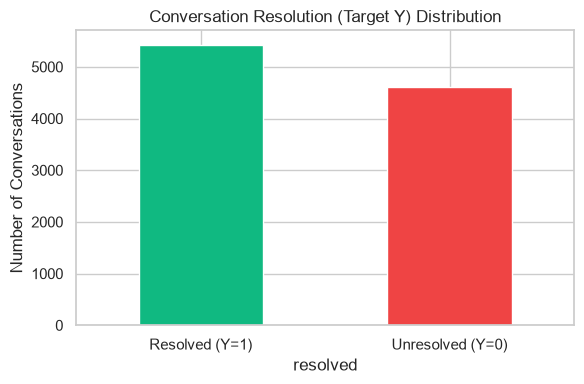

In [5]:
# Distribution of target variable Y across splits
split_counts = pd.crosstab(df_convos["split"], df_convos["resolved"])
split_resolution = (
    pd.crosstab(df_convos["split"], df_convos["resolved"], normalize="index") * 100
)

print("--- Resolution Counts ---")
print(split_counts)
print("\n--- Resolution Percentages ---")
print(split_resolution.round(2))

fig, ax = plt.subplots(figsize=(6, 4))
df_convos["resolved"].value_counts().plot(
    kind="bar", color=["#10b981", "#ef4444"], ax=ax
)
ax.set_title("Conversation Resolution (Target Y) Distribution")
ax.set_xticklabels(["Resolved (Y=1)", "Unresolved (Y=0)"], rotation=0)
ax.set_ylabel("Number of Conversations")
plt.tight_layout()
plt.show()

## 3. Intent & Flow Breakdown

Which customer intents have the highest friction and lowest resolution rates?

In [6]:
intent_stats = (
    df_convos.groupby("intent")
    .agg(
        total=("convo_id", "count"),
        resolved_rate=("resolved", "mean"),
        escalation_rate=("has_escalation", "mean"),
        avg_turns=("num_turns", "mean"),
    )
    .sort_values("total", ascending=False)
)

print("Top 10 Intents by Volume:")
display(
    intent_stats.head(10).style.format(
        {"resolved_rate": "{:.1%}", "escalation_rate": "{:.1%}", "avg_turns": "{:.1f}"}
    )
)

print("\nIntents with Lowest Resolution Rates (Highest Friction):")
display(
    intent_stats.sort_values("resolved_rate")
    .head(10)
    .style.format(
        {"resolved_rate": "{:.1%}", "escalation_rate": "{:.1%}", "avg_turns": "{:.1f}"}
    )
)

Top 10 Intents by Volume:


,total,resolved_rate,escalation_rate,avg_turns
intent,,,,
recover_username,361,91.4%,0.6%,18.2
reset_2fa,351,84.9%,0.0%,20.6
recover_password,336,95.2%,0.0%,22.8
boots,281,67.6%,3.9%,16.4
membership,281,72.6%,0.0%,17.6
pricing,277,65.0%,0.7%,16.3
policy,272,60.7%,0.4%,17.5
status,268,39.2%,0.7%,26.1
credit_card,266,13.2%,0.4%,20.0



Intents with Lowest Resolution Rates (Highest Friction):


,total,resolved_rate,escalation_rate,avg_turns
intent,,,,
status_active,30,0.0%,0.0%,26.4
slow_speed,250,0.0%,50.0%,20.8
out_of_stock_general,140,0.0%,97.1%,20.2
search_results,259,0.0%,24.7%,21.5
manage_extension,165,1.2%,32.7%,24.1
out_of_stock_one_item,127,2.4%,91.3%,21.5
refund_status,179,5.6%,0.6%,20.1
shopping_cart,251,6.0%,0.4%,19.4
credit_card,266,13.2%,0.4%,20.0


## 4. Visual Conversation Inspection

Using `abcd.get_conversation(convo_id)`, you can inspect any conversation with interactive chat bubbles and action badges right inside your notebook.

In [7]:
# Inspect an unresolved conversation with escalation (convo_id=3592)
d_unresolved = abcd.get_conversation(3592)
d_unresolved

## 5. Next Steps for Feature Engineering (Phase 2 & 3)

Now that the data is ready and queryable, the next phase in `ANALYSIS_PLAN.md` is to engineer the feature matrix $X$:
1. **DST Features:**
   - `slot_filling_latency`: Turns elapsed before mandatory slots are provided.
   - `slot_revision_count`: Corrections of previously stated slot values.
   - `upfront_slot_density`: Slots provided in turns 1–2.
2. **AST Features:**
   - `sop_edit_distance`: Levenshtein distance between observed action sequence (`actions_taken`) and optimal guideline path (`canonical_actions`).
   - `action_thrashing_count`: Repeated consecutive actions.
3. **Semantic & Emotional Trajectory:**
   - `semantic_alignment_score`: User-agent cross-encoder alignment.
   - `frustration_velocity`: Emotional trajectory slope.

All foundational data structures are in place!

In [8]:
df_actions = abcd.load_actions()

# sample conversation
convo = df_convos[df_convos["convo_id"] == 3592].iloc[0]
canonical_actions = convo["canonical_actions"]

required_slots = []
for act in canonical_actions:
    action_row = df_actions[df_actions["action_name"] == act]                                                    
    if not action_row.empty:                                                                                     
        for s in action_row["required_slots"].iloc[0]:                                                           
            if s not in required_slots:                                                                          
                required_slots.append(s) 

print(convo[['intent', 'flow']].values)
print(required_slots)

['return_size' 'product_defect']
['customer_name', 'account_id', 'username', 'email', 'order_id', 'membership_level', 'details_slotval', 'full_address', 'pin_number', 'security_answer', 'order_slotval', 'change_option', 'amount', 'payment_method']


In [9]:
df_turns_to_be_extracted = (
    df_turns[df_turns['convo_id'].isin([3592, 3647])]
)
df_turns_to_be_extracted

,convo_id,turn_id,turn_count,split,speaker,text,text_delexed,flow,intent,next_step,action_name,action_values,slot_tags,char_len,word_len
0,3592,0,1,train,agent,Hi!,hi!,product_defect,return_size,retrieve_utterance,NaN,NaN,NaN,3,1
1,3592,1,2,train,agent,How can I help you?,how can i help you?,product_defect,return_size,retrieve_utterance,NaN,NaN,NaN,19,5
2,3592,2,3,train,customer,"Hi! I need to return an item, can you help me ...","hi! i need to return an item, can you help me ...",product_defect,return_size,NaN,NaN,NaN,NaN,56,13
3,3592,3,4,train,agent,"sure, may I have your name please?","sure, may i have your name please?",product_defect,return_size,retrieve_utterance,NaN,NaN,NaN,34,7
4,3592,4,5,train,customer,Crystal Minh,crystal minh,product_defect,return_size,NaN,NaN,NaN,NaN,12,2
5,3592,5,6,train,agent,"thanks, may I ask the reason for the return?","thanks, may i ask the reason for the return?",product_defect,return_size,retrieve_utterance,NaN,NaN,NaN,44,9
6,3592,6,7,train,action,Account has been pulled up for Crystal Minh.,account has been pulled up for crystal minh.,product_defect,return_size,take_action,pull-up-account,"[""crystal minh""]",NaN,44,8
7,3592,7,8,train,customer,I got the wrong size.,i got the wrong size.,product_defect,return_size,NaN,NaN,NaN,NaN,21,5
8,3592,8,9,train,agent,"ok, may I have your username, email address an...","ok, may i have your username, email address an...",product_defect,return_size,retrieve_utterance,NaN,NaN,NaN,64,12
9,3592,9,10,train,customer,Username: cminh730,username: <username>,product_defect,return_size,NaN,NaN,NaN,username,18,2


In [10]:
import abcd_helper as abcd
from nlp import extract_customer_contexts, get_customer_turn_context

contexts = extract_customer_contexts(df_turns, min_prior_agent_utterances=2)                                                                                                                                                                    
# 1. Single customer turn context                                                                                                                                   
ctx = get_customer_turn_context(                                                                                                                                    
    df_turns_to_be_extracted, convo_id=3647, current_turn_idx=1, min_prior_agent_utterances=2                                                                                                     
)                                                                                                                                                                   
print(ctx)                                                                                                                                            
                                                                                                                                                                    
# 2. Batch extraction for all customer turns in the conversation                                                                                                    
contexts = extract_customer_contexts(df_turns_to_be_extracted, min_prior_agent_utterances=2)                                                                                        
print(f"Captured {len(contexts)} customer turns with rolling context.")

DialogueTurnContext(turn_id=1, customer_text='Hello. I have a really cool party coming up. And I need some new clothes ASAP. I am thinking of ordering them to come by overnight shipping', customer_text_delexed='hello. i have a really cool party coming up. and i need some new clothes asap. i am thinking of ordering them to come by overnight shipping', convo_id=3647, prior_turns=[{'convo_id': 3647, 'turn_id': 0, 'turn_count': 1, 'split': 'train', 'speaker': 'agent', 'text': 'Hello, how can i help you', 'text_delexed': 'hello, how can i help you', 'flow': 'storewide_query', 'intent': 'pricing', 'next_step': 'retrieve_utterance', 'action_name': nan, 'action_values': nan, 'slot_tags': nan, 'char_len': 25, 'word_len': 6}], prior_agent_turns=[{'convo_id': 3647, 'turn_id': 0, 'turn_count': 1, 'split': 'train', 'speaker': 'agent', 'text': 'Hello, how can i help you', 'text_delexed': 'hello, how can i help you', 'flow': 'storewide_query', 'intent': 'pricing', 'next_step': 'retrieve_utterance', '

In [11]:
print(contexts[0].get_full_document(strip_prior_customer_utterances=True))

[AGENT]: Hi!
[AGENT]: How can I help you?
[CUSTOMER (CURRENT)]: Hi! I need to return an item, can you help me with that?


In [12]:
print(contexts[4].get_full_document(strip_prior_customer_utterances=True))

[AGENT]: thanks, may I ask the reason for the return?
[AGENT]: ok, may I have your username, email address and order ID please?
[CUSTOMER (CURRENT)]: cminh730@email.com


In [13]:
all_slots = abcd.load_intent_slots()['all_slots'].tolist()
all_slots_unique = []
for slots in all_slots:
    all_slots_unique += list(slots)
    all_slots_unique = list(set(all_slots_unique))
all_slots_unique

['reason_slotval',
 'company_team',
 'storewide_query',
 'order_slotval',
 'account_id',
 'shipping_option',
 'order_id',
 'email',
 'full_address',
 'refund_target',
 'account_slotval',
 'single_item_query',
 'username',
 'pin_number',
 'security_answer',
 'phone',
 'product',
 'customer_name',
 'street_address',
 'payment_method',
 'membership_level',
 'change_option',
 'zip_code',
 'amount',
 'details_slotval']

In [14]:
from abcd_helper.loader import load_intent_slots

load_intent_slots(intent='return_size', flow='product_defect')

{'flow': 'product_defect',
 'intent': 'return_size',
 'canonical_actions': array(['pull-up-account', 'validate-purchase', 'membership',
        'enter-details', 'update-order'], dtype=object),
 'mandatory_slots': array([array(['customer_name', 'account_id'], dtype=object),
        array(['username'], dtype=object), array(['email'], dtype=object),
        array(['order_id'], dtype=object),
        array(['full_address', 'street_address'], dtype=object)],
       dtype=object),
 'num_mandatory_slots': 5,
 'agent_action_slots': array(['membership_level', 'details_slotval', 'order_slotval'],
       dtype=object),
 'all_slots': array(['customer_name', 'account_id', 'username', 'email', 'order_id',
        'membership_level', 'details_slotval', 'full_address',
        'pin_number', 'security_answer', 'order_slotval', 'change_option',
        'amount', 'payment_method'], dtype=object),
 'sop_summary': 'Customer returns item due to sizing mismatch. Pull up account, validate purchase, verify mem

In [15]:
abcd.load_intent_slots().loc[0]

flow                                                      account_access
intent                                                  recover_username
canonical_actions                     [pull-up-account, verify-identity]
mandatory_slots        [[customer_name, account_id], [zip_code], [ema...
num_mandatory_slots                                                    3
agent_action_slots                                                    []
all_slots                [customer_name, account_id, order_id, zip_code]
sop_summary            Customer lost username. Pull up account using ...
Name: 0, dtype: object

In [16]:
df_trun_slot_states = pd.read_parquet("../data/processed/turn_slot_states.parquet")
df_trun_slot_states.head()

,convo_id,turn_id,active_slots,extracted_values
0,3592,2,"[email, phone, storewide_query, customer_name,...","{'email': True, 'phone': True, 'storewide_quer..."
1,3592,4,[username],{'username': True}
2,3592,7,[],{}
3,3592,9,[username],{'username': True}
4,3592,10,"[username, email, order_id]","{'username': True, 'email': 'cminh730@email.co..."


In [17]:
df_convos.head()

,convo_id,split,flow,intent,scenario_subflow,num_turns,num_customer_turns,num_agent_turns,num_action_turns,customer_name,username,email,phone,member_level,account_id,order_id,order_amount,order_products,order_city,order_state,order_zip,actions_taken,num_actions,canonical_actions,canonical_terminal,actual_terminal,has_escalation,reached_canonical_terminal,resolved
0,3592,train,product_defect,return_size,return_size,29,13,12,4,crystal minh,cminh730,cminh730@email.com,(977) 625-2661,bronze,NaN,3348917502,94.0,michael_kors jeans,san mateo,ny,75227,"[pull-up-account, validate-purchase, enter-det...",4,"[pull-up-account, validate-purchase, membershi...",update-order,notify-team,True,False,0
1,9489,train,product_defect,refund_status,refund_status,21,10,9,2,alessandro phoenix,aphoenix939,aphoenix939@email.com,(727) 760-7806,gold,NaN,7916676427,69.0,michael_kors shirt,la fayette,tx,86229,"[pull-up-account, validate-purchase]",2,"[pull-up-account, validate-purchase, notify-te...",update-order,validate-purchase,False,False,0
2,3695,train,storewide_query,timing,timing_4,22,8,11,3,joyce wu,NaN,NaN,(859) 787-9085,bronze,NaN,NaN,NaN,NaN,raleigh,mi,14573,"[search-faq, search-timing, select-faq]",3,"[search-faq, search-timing, select-faq]",select-faq,select-faq,False,True,1
3,5798,train,shipping_issue,manage,manage,23,7,12,4,crystal minh,cminh948,cminh948@email.com,(656) 332-6844,silver,xjiw8ufp3b,4870952797,227.0,"tommy_hilfiger shirt, michael_kors shirt, mich...",newark,mi,85971,"[pull-up-account, shipping-status, validate-pu...",4,"[pull-up-account, shipping-status, validate-pu...",update-order,update-order,False,True,1
4,3647,train,storewide_query,pricing,pricing_3,23,13,7,3,norman bouchard,NaN,NaN,(480) 983-3323,guest,NaN,NaN,182.0,"michael_kors jeans, tommy_hilfiger jeans, tomm...",raleigh,ca,46681,"[search-faq, search-pricing, select-faq]",3,"[search-faq, search-pricing, select-faq]",select-faq,select-faq,False,True,1


In [18]:
select_convo_id = 3592
select_convo = abcd.get_conversation(select_convo_id)
convo_slots = df_trun_slot_states[df_trun_slot_states['convo_id']==select_convo_id].set_index("turn_id")["active_slots"].to_dict()
select_convo.render(labels=convo_slots)

<ConversationView: 29 turns>

In [19]:
(
    df_turns[df_turns['convo_id']==3592]
)[['convo_id', 'turn_id', 'speaker', 'text', 'slot_tags']]


,convo_id,turn_id,speaker,text,slot_tags
0,3592,0,agent,Hi!,NaN
1,3592,1,agent,How can I help you?,NaN
2,3592,2,customer,"Hi! I need to return an item, can you help me ...",NaN
3,3592,3,agent,"sure, may I have your name please?",NaN
4,3592,4,customer,Crystal Minh,NaN
5,3592,5,agent,"thanks, may I ask the reason for the return?",NaN
6,3592,6,action,Account has been pulled up for Crystal Minh.,NaN
7,3592,7,customer,I got the wrong size.,NaN
8,3592,8,agent,"ok, may I have your username, email address an...",NaN
9,3592,9,customer,Username: cminh730,username
